# HDS → TouchSim

Pipeline: fMRI → decoding → **HDS pattern (binary tensor)** → TouchSim → spike trains → evaluation.

- TouchSim không có trên PyPI nên cài từ GitHub `hsaal/touchsim`.
- **Đừng ghi đè `ts.hand_surface.pxl_per_mm`** (≈ 2.18 px/mm, ứng với bàn tay ~209 mm của TouchSim).
- **Chuẩn hoá kích thước thật:** bàn tay TouchSim dài ~209 mm, trong khi trung bình thật là **189 mm**. Ta scale đều (giữ nguyên tỉ lệ bàn tay) với `HAND_SCALE = 189 / chiều dài đo được` (~0.904). Ảnh bàn tay giữ nguyên, nhưng 1 mm thật giờ = `ts_ppm / HAND_SCALE` ≈ 2.41 px, nên HDS 50×80 mm chiếm phần lớn hơn của bàn tay và được đặt lại vị trí.
- HDS luôn là kích thước thật (50×80 mm, pin Ø10, pitch 15, sâu 1 mm); chỉ bàn tay được thu về 189 mm. Khi mô phỏng, vị trí *và bán kính* pin cùng được đổi sang đơn vị TouchSim bằng cách chia cho HAND_SCALE (pitch ≈ 16.6, bán kính ≈ 5.53 TS-mm), nên tỉ lệ pin/pitch/tay đúng như thật. Độ sâu 1 mm giữ nguyên. Afferent (receptive field, mật độ) vẫn ở đơn vị gốc của TouchSim.
- Quần thể afferent được cân lại theo paper TouchSim: SA1 : RA : PC = 2 : 4 : 1 (SA1 gấp đôi PC, RA gấp đôi SA1) bằng cách subsample ngẫu nhiên có seed (`CLASS_RATIO`, `make_population(class_ratio=None)` để tắt).
- **Kích thích theo từng hàng:** hàng 0 (trên cùng) trước, rồi lần lượt các hàng sau. Mỗi hàng: 0.2 s xuống, 0.6 s giữ, 0.2 s lên (1.0 s), các pin hoạt động của hàng đó chuyển động cùng lúc; xong hàng này mới tới hàng kế. Chữ số 5 hàng kéo dài 5 s. Stimulus là một `ts.Stimulus` duy nhất, trace của mỗi pin bằng 0 ngoài khung thời gian của hàng nó thuộc về.
- Hai hệ toạ độ: *pixel* (ảnh bàn tay, x 0–450, y 70–525) và *hand* (mm, dùng cho Stimulus/Afferent). Đổi bằng `hand_surface.pixel2hand / hand2pixel`.

In [1]:
!pip install -q git+https://github.com/hsaal/touchsim.git
import os, json, types, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
import touchsim as ts
from dataclasses import dataclass
print("touchsim loaded from", ts.__file__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
touchsim loaded from /usr/local/lib/python3.13/dist-packages/touchsim/__init__.py


## 1. HDS: thông số, mẫu chữ số, vị trí pin, tìm vị trí vừa vùng tay

In [2]:
ROWS, COLS = 5, 3


@dataclass(frozen=True)
class HDSSpec:
    pin_diameter_mm: float = 10.0
    pitch_mm: float = 15.0
    depth_mm: float = 1.0
    pressure_mpa: float = 0.3   # not used by the simulation
    ramp_s: float = 0.2
    hold_s: float = 0.6
    width_mm: float = 50.0
    height_mm: float = 80.0
    rows: int = ROWS
    cols: int = COLS

    @property
    def row_duration_s(self) -> float:
        """One row: ramp down + hold + ramp up."""
        return 2 * self.ramp_s + self.hold_s

    @property
    def duration_s(self) -> float:
        """Whole pattern: rows are presented one after another."""
        return self.rows * self.row_duration_s

    def pin_offsets_mm(self) -> np.ndarray:
        """(rows, cols, 2) pin centers in mm relative to the display center (x right, y up)."""
        xs = (np.arange(self.cols) - (self.cols - 1) / 2) * self.pitch_mm
        ys = ((self.rows - 1) / 2 - np.arange(self.rows)) * self.pitch_mm  # row 0 on top
        gx, gy = np.meshgrid(xs, ys)
        return np.stack([gx, gy], axis=-1)


# 5 rows x 3 cols for digits 0-9
_GLYPHS = {
    0: ["111", "101", "101", "101", "111"],
    1: ["010", "010", "010", "010", "010"],
    2: ["111", "001", "111", "100", "111"],
    3: ["111", "001", "111", "001", "111"],
    4: ["101", "101", "111", "001", "001"],
    5: ["111", "100", "111", "001", "111"],
    6: ["100", "100", "111", "101", "111"],
    7: ["111", "001", "001", "001", "001"],
    8: ["111", "101", "111", "101", "111"],
    9: ["111", "101", "111", "001", "001"],
}

def digit_tensor(d: int) -> np.ndarray:
    """Binary tensor (5, 3) of dtype uint8 for digit d."""
    return np.array([[int(c) for c in row] for row in _GLYPHS[d]], dtype=np.uint8)


def pin_positions_px(spec: HDSSpec, center_px, pxl_per_mm: float = 1.0) -> np.ndarray:
    """(rows, cols, 2) pin centers in hand-surface pixels."""
    return np.asarray(center_px, float) + spec.pin_offsets_mm() * pxl_per_mm


def fit_to_region(spec: HDSSpec, region_mask_fn, search_box, pxl_per_mm=1.0, step_px=5):
    """Search for the display center that keeps the most pins inside a region.

    region_mask_fn(x, y) -> bool says whether a hand-surface point (px) lies in the target
    region. search_box = (xmin, xmax, ymin, ymax) in px. Returns (best_center, n_inside, grid)
    where grid maps every tried center to its pin count, so the choice can be inspected.
    """
    xmin, xmax, ymin, ymax = search_box
    best, best_n, grid = None, -1, {}
    for cx in np.arange(xmin, xmax + 1, step_px):
        for cy in np.arange(ymin, ymax + 1, step_px):
            pts = pin_positions_px(spec, (cx, cy), pxl_per_mm).reshape(-1, 2)
            n = sum(bool(region_mask_fn(x, y)) for x, y in pts)
            grid[(cx, cy)] = n
            if n > best_n:
                best, best_n = (cx, cy), n
    # many centers often tie for the max: take the one closest to the middle of the tied set,
    # which keeps the display away from the region edges
    tied = np.array([k for k, v in grid.items() if v == best_n], float)
    best = tuple(tied[np.argmin(((tied - tied.mean(axis=0)) ** 2).sum(axis=1))])
    return best, best_n, grid


def bounding_box_px(spec: HDSSpec, center_px, pxl_per_mm=1.0):
    """Outer box of the display (the 'box to fit the HDS'): (xmin, ymin, xmax, ymax) px."""
    cx, cy = center_px
    return (cx - spec.width_mm / 2 * pxl_per_mm, cy - spec.height_mm / 2 * pxl_per_mm,
            cx + spec.width_mm / 2 * pxl_per_mm, cy + spec.height_mm / 2 * pxl_per_mm)

## 2. Visualization HDS

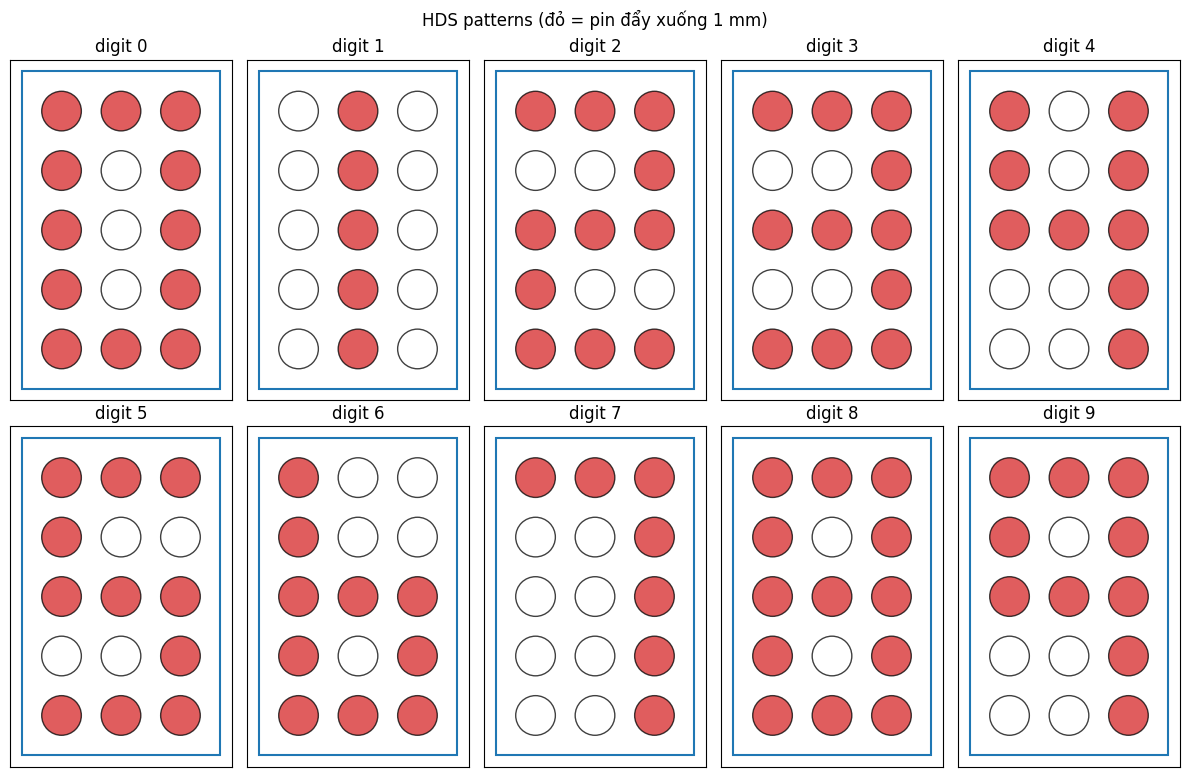

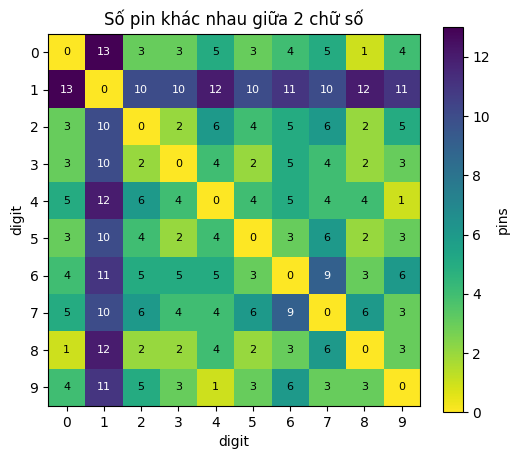

Cặp gần nhau nhất: 0 vs 8 (1 pin khác)


In [3]:
spec = HDSSpec()
def draw_pins(ax, tensor, center=(0, 0), ppm=1.0, ec="k", zorder=1, alpha=.75):
    pos = pin_positions_px(spec, center, ppm)
    x0, y0, x1, y1 = bounding_box_px(spec, center, ppm)
    ax.add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec="tab:blue", lw=1.5, zorder=zorder))
    for r in range(spec.rows):
        for c in range(spec.cols):
            ax.add_patch(Circle(pos[r, c], spec.pin_diameter_mm/2*ppm, fc="tab:red" if tensor[r, c] else "none", ec=ec, alpha=alpha, zorder=zorder))
    return x0, y0, x1, y1

# 2.1 Cả 10 chữ số trên HDS (mm)
fig, axes = plt.subplots(2, 5, figsize=(12, 8))
for ax, d in zip(axes.ravel(), range(10)):
    x0, y0, x1, y1 = draw_pins(ax, digit_tensor(d))
    ax.set_xlim(x0-3, x1+3); ax.set_ylim(y0-3, y1+3); ax.set_aspect("equal"); ax.set_title(f"digit {d}"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("HDS patterns (đỏ = pin đẩy xuống 1 mm)"); plt.tight_layout(); plt.show()

# 2.2 Mỗi cặp chữ số khác nhau bao nhiêu pin (Hamming) -> cặp nào decoder dễ nhầm
H = np.array([[int((digit_tensor(a) != digit_tensor(b)).sum()) for b in range(10)] for a in range(10)])
fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(H, cmap="viridis_r")
for i in range(10):
    for j in range(10):
        ax.text(j, i, H[i, j], ha="center", va="center", color="w" if H[i, j] > H.max()/2 else "k", fontsize=8)
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xlabel("digit"); ax.set_ylabel("digit")
ax.set_title("Số pin khác nhau giữa 2 chữ số"); plt.colorbar(im, label="pins"); plt.show()
off = H + np.eye(10, dtype=int)*99; a, b = np.unravel_index(off.argmin(), off.shape)
print(f"Cặp gần nhau nhất: {a} vs {b} ({H[a,b]} pin khác)")

## 3. Kiểm tra nhanh (tests)

In [4]:
def test_digits_shape_and_binary():
    for d in range(10):
        t = digit_tensor(d)
        assert t.shape == (5, 3) and set(np.unique(t)) <= {0, 1}
    assert digit_tensor(8).sum() == 13 and digit_tensor(0).sum() == 12


def test_geometry_matches_spec():
    s = HDSSpec()
    p = pin_positions_px(s, (0, 0), 1.0)
    assert np.isclose(p[0, 1, 0] - p[0, 0, 0], 15.0)       # pitch
    assert np.isclose(p[0, 0, 1] - p[1, 0, 1], 15.0)
    x0, y0, x1, y1 = bounding_box_px(s, (0, 0))
    assert (x1 - x0, y1 - y0) == (50.0, 80.0)
    # outermost pin edges sit inside the 50x80 box
    assert p[..., 0].max() + 5 <= x1 and p[..., 1].max() + 5 <= y1


def test_scale_applies():
    s = HDSSpec()
    p2 = pin_positions_px(s, (100, 100), 2.0)
    assert np.isclose(p2[0, 1, 0] - p2[0, 0, 0], 30.0)


def test_fit_finds_inside_position():
    s = HDSSpec()
    inside = lambda x, y: 100 <= x <= 300 and 200 <= y <= 500
    c, n, _ = fit_to_region(s, inside, (80, 320, 180, 520), step_px=10)
    assert n == 15 and 100 <= c[0] <= 300

def test_timing():
    s = HDSSpec()
    assert s.ramp_s == 0.2 and s.hold_s == 0.6
    assert np.isclose(s.row_duration_s, 1.0) and np.isclose(s.duration_s, 5.0)

for f in [test_digits_shape_and_binary, test_geometry_matches_spec, test_scale_applies, test_fit_finds_inside_position, test_timing]:
    f()
print('all HDS tests passed')

all HDS tests passed


## 4. TouchSim adapter (dựa trên mã nguồn hsaal/touchsim)

In [5]:
import numpy as np

PALM_REGIONS = ["Pw1_p", "Pw2_p", "Pw3_p", "Pw4_p", "Pp1_p", "Pp2_p"]


def load_touchsim():
    import touchsim as ts
    return ts


REAL_HAND_LENGTH_MM = 189.0   # mean hand length, wrist to middle fingertip (TouchSim hand is ~209 mm)


def ts_px_per_mm(ts) -> float:
    """TouchSim's own scale (px per *TouchSim* mm, ~2.18). Never overwrite it."""
    return float(ts.hand_surface.pxl_per_mm)


def ts_hand_length_mm(ts) -> float:
    """Length of the TouchSim hand outline in TouchSim mm (~209)."""
    b = np.vstack(ts.hand_surface.boundary) / ts_px_per_mm(ts)
    return float(np.ptp(b[:, 1]))


def hand_scale(ts) -> float:
    """Uniform factor (<1) shrinking the TouchSim hand to the realistic length (ratio preserved)."""
    return REAL_HAND_LENGTH_MM / ts_hand_length_mm(ts)


def px_per_mm(ts) -> float:
    """Pixels per REAL mm on the hand image. The image is fixed, but the hand is now 189 mm
    long instead of 209 mm, so one real mm covers more pixels than before."""
    return ts_px_per_mm(ts) / hand_scale(ts)


def pins_px(ts, spec: HDSSpec, center_px):
    """(rows, cols, 2) pin centers in pixel space."""
    return pin_positions_px(spec, center_px, px_per_mm(ts))


def pins_hand_mm(ts, spec: HDSSpec, center_px):
    """(rows, cols, 2) pin centers in hand space (mm), what TouchSim stimuli need."""
    p = pins_px(ts, spec, center_px)
    flat = ts.hand_surface.pixel2hand(p.reshape(-1, 2))
    return flat.reshape(p.shape)


def region_mask_fn(ts, tags=PALM_REGIONS, box=(0, 450, 0, 560)):
    """Returns f(x_px, y_px) -> bool: is the pixel inside any of the named hand regions?
    Rasterised once at 1 px so the position search is fast."""
    hs = ts.hand_surface
    x0, x1, y0, y1 = box
    xs, ys = np.arange(x0, x1 + 1), np.arange(y0, y1 + 1)
    gx, gy = np.meshgrid(xs, ys, indexing="ij")
    pts_px = np.column_stack([gx.ravel(), gy.ravel()]).astype(float)
    _, ids = hs.locate(hs.pixel2hand(pts_px))
    want = [hs.tags.index(t) for t in tags]
    inside = np.isin(ids, want).reshape(gx.shape)

    def f(x, y):
        i, j = int(round(x)) - x0, int(round(y)) - y0
        return 0 <= i < inside.shape[0] and 0 <= j < inside.shape[1] and bool(inside[i, j])
    return f


def build_stimulus(ts, tensor, spec: HDSSpec, center_px, fs=5000):
    """Row-by-row stimulus. Row 0 (top) first, then the next rows; within a row all active pins
    move together: ramp down (ramp_s), hold (hold_s), ramp up (ramp_s), then the next row starts."""
    hand = pins_hand_mm(ts, spec, center_px)
    pin_radius_ts = spec.pin_diameter_mm / 2 / hand_scale(ts)   # real mm -> TouchSim mm
    n_ramp, n_hold = int(round(spec.ramp_s * fs)), int(round(spec.hold_s * fs))
    pulse = spec.depth_mm * np.concatenate([np.linspace(0, 1, n_ramp), np.ones(n_hold),
                                            np.linspace(1, 0, n_ramp)])
    row_n = len(pulse)
    total_n = row_n * tensor.shape[0]
    locs, traces = [], []
    for r in range(tensor.shape[0]):
        for c in range(tensor.shape[1]):
            if not tensor[r, c]:
                continue
            trace = np.zeros(total_n)
            trace[r * row_n:(r + 1) * row_n] = pulse
            locs.append(hand[r, c])
            traces.append(trace)
    if not traces:
        raise ValueError("Tensor has no active pins.")
    return ts.Stimulus(location=np.array(locs), trace=np.array(traces), fs=fs,
                       pin_radius=pin_radius_ts)


CLASS_RATIO = {"SA1": 2, "RA": 4, "PC": 1}   # Saal et al. 2017: SA1 = 2x PC, RA = 2x SA1


def balance_classes(pop, ratio=CLASS_RATIO, seed=0):
    """Randomly subsample afferents so the class counts follow `ratio` (as many as possible)."""
    cls = np.array(pop.affclass)
    unit = min((cls == k).sum() / w for k, w in ratio.items())
    rng = np.random.default_rng(seed)
    sel = np.zeros(len(cls), bool)
    for k, w in ratio.items():
        sel[rng.choice(np.where(cls == k)[0], int(round(unit * w)), replace=False)] = True
    return pop[sel]


def make_population(ts, spec: HDSSpec, center_px, margin_mm=20.0, density_multiplier=1.0,
                    class_ratio=CLASS_RATIO, seed=0):
    """Hand afferents (SA1, RA, PC) lying under / near the HDS box (+ margin), to keep the
    simulation fast. Build once per HDS position and reuse for every digit so responses
    are comparable."""
    pop = ts.affpop_hand(density_multiplier=density_multiplier)
    ppm = px_per_mm(ts)
    loc_px = ts.hand_surface.hand2pixel(pop.location)
    x0, y0, x1, y1 = bounding_box_px(spec, center_px, ppm)
    m = margin_mm * ppm
    keep = ((loc_px[:, 0] >= x0 - m) & (loc_px[:, 0] <= x1 + m) &
            (loc_px[:, 1] >= y0 - m) & (loc_px[:, 1] <= y1 + m))
    if not keep.any():
        raise ValueError("No afferents near the HDS - is the center on the hand?")
    pop = pop[keep]
    return balance_classes(pop, class_ratio, seed) if class_ratio else pop


def respond(ts, stim, pop):
    return pop.response(stim)

tsa = types.SimpleNamespace(PALM_REGIONS=PALM_REGIONS, ts_px_per_mm=ts_px_per_mm,
    hand_scale=hand_scale, ts_hand_length_mm=ts_hand_length_mm, load_touchsim=load_touchsim, px_per_mm=px_per_mm,
    pins_px=pins_px, pins_hand_mm=pins_hand_mm, region_mask_fn=region_mask_fn,
    build_stimulus=build_stimulus, balance_classes=balance_classes, make_population=make_population, respond=respond)

## 6. Bàn tay thật, 6 vùng palm, và HDS

TouchSim hand: 209.3 mm long, 2.184 px/mm
Scale to real hand (189 mm): HAND_SCALE = 0.9032 -> 2.418 px per real mm
HDS 50x80 mm = 121x193 px on the hand image
Tâm HDS tốt nhất (px): (236.0, 196.0) -> 15/15 pin nằm trong 6 vùng palm


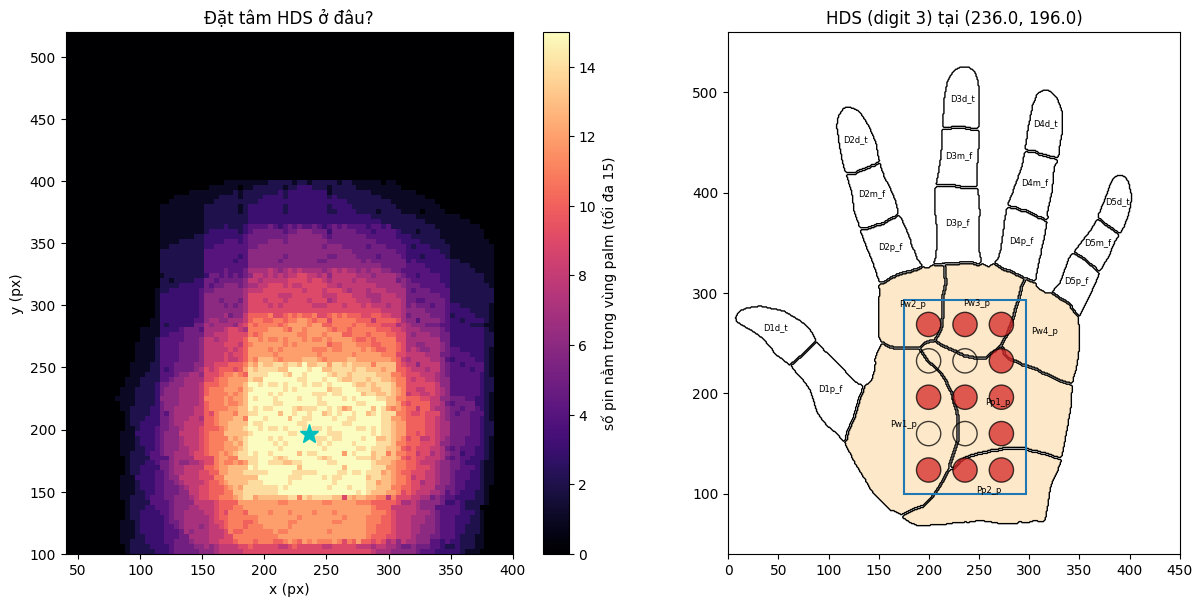

In [6]:
hs = ts.hand_surface
PPM = tsa.px_per_mm(ts)
print(f"TouchSim hand: {tsa.ts_hand_length_mm(ts):.1f} mm long, {tsa.ts_px_per_mm(ts):.3f} px/mm")
print(f"Scale to real hand ({REAL_HAND_LENGTH_MM:.0f} mm): HAND_SCALE = {tsa.hand_scale(ts):.4f} -> {PPM:.3f} px per real mm")
print(f"HDS {spec.width_mm:.0f}x{spec.height_mm:.0f} mm = {spec.width_mm*PPM:.0f}x{spec.height_mm*PPM:.0f} px on the hand image")

def plot_hand(ax=None, highlight=tsa.PALM_REGIONS, labels=True):
    ax = ax or plt.subplots(figsize=(6, 7))[1]
    for b, poly in enumerate(hs.boundary):
        ax.add_patch(Polygon(poly, closed=True, fc="#fde9c9" if hs.tags[b] in highlight else "none", ec="k", lw=1))
    if labels:
        for t, (x, y) in zip(hs.tags, hs.hand2pixel(hs.centers)):
            ax.text(x, y, t, fontsize=6, ha="center")
    ax.set_xlim(0, 450); ax.set_ylim(40, 560); ax.set_aspect("equal")
    return ax

# 6.1 Tìm vị trí HDS đặt vừa 6 vùng palm (Pw1-4, Pp1-2); mask lấy từ vùng tay thật của TouchSim
mask = tsa.region_mask_fn(ts)
best, n, grid = fit_to_region(spec, mask, (40, 400, 100, 520), pxl_per_mm=PPM, step_px=4)
CENTER = (float(best[0]), float(best[1]))
print(f"Tâm HDS tốt nhất (px): {CENTER} -> {n}/15 pin nằm trong 6 vùng palm")

xs = sorted({k[0] for k in grid}); ys = sorted({k[1] for k in grid})
M = np.array([[grid[(x, y)] for x in xs] for y in ys])
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
im = axes[0].imshow(M, origin="lower", extent=[xs[0], xs[-1], ys[0], ys[-1]], aspect="equal", cmap="magma")
axes[0].plot(*CENTER, "c*", ms=14); plt.colorbar(im, ax=axes[0], label="số pin nằm trong vùng palm (tối đa 15)")
axes[0].set_title("Đặt tâm HDS ở đâu?"); axes[0].set_xlabel("x (px)"); axes[0].set_ylabel("y (px)")
ax = plot_hand(axes[1]); draw_pins(ax, digit_tensor(3), CENTER, PPM); axes[1].set_title(f"HDS (digit 3) tại {CENTER}")
plt.tight_layout(); plt.show()

## 6b. Từng chữ số 0→9 trên bàn tay đúng kích thước thật (mm) + PDF in 1:1

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Circle, Rectangle, Polygon


def hand_dimensions_mm(ts):
    """Real-world size of the TouchSim hand outline, in mm."""
    hs = ts.hand_surface
    ppm = tsa.px_per_mm(ts)          # real mm (hand scaled to 189 mm)
    allb = np.vstack(hs.boundary) / ppm
    d3 = np.vstack([hs.boundary[i] for i, t in enumerate(hs.tags) if t.startswith("D3")]) / ppm
    return {"hand_width_mm": float(np.ptp(allb[:, 0])), "hand_length_mm": float(np.ptp(allb[:, 1])),
            "middle_finger_mm": float(np.ptp(d3[:, 1])), "bbox_mm": (allb[:, 0].min(), allb[:, 0].max(),
                                                                  allb[:, 1].min(), allb[:, 1].max())}


def draw_hand_mm(ax, ts, highlight=(), labels=False):
    hs = ts.hand_surface; ppm = tsa.px_per_mm(ts)
    for b, poly in enumerate(hs.boundary):
        ax.add_patch(Polygon(poly / ppm, closed=True, ec="k", lw=1,
                             fc="#fde9c9" if hs.tags[b] in highlight else "none"))
    if labels:
        for t, (x, y) in zip(hs.tags, hs.hand2pixel(hs.centers) / ppm):
            ax.text(x, y, t, fontsize=6, ha="center", color="0.4")


def draw_hds_mm(ax, ts, digit, center_px, spec=None, lw=1.5):
    """Box + pins of one digit; coordinates in mm (centre given in hand-image px)."""
    spec = spec or HDSSpec(); ppm = tsa.px_per_mm(ts); t = digit_tensor(digit)
    pos = pin_positions_px(spec, center_px, ppm) / ppm
    x0, y0, x1, y1 = np.array(bounding_box_px(spec, center_px, ppm)) / ppm
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="tab:blue", lw=lw, zorder=4))
    for r in range(spec.rows):
        for c in range(spec.cols):
            ax.add_patch(Circle(pos[r, c], spec.pin_diameter_mm / 2, zorder=5,
                                fc="tab:red" if t[r, c] else "none", ec="k", alpha=.8 if t[r, c] else 1, lw=.8))
    return (x0, y0, x1, y1)


def scale_bar(ax, x, y, length=50, label=None):
    ax.plot([x, x + length], [y, y], "k-", lw=2, zorder=6)
    for xx in (x, x + length):
        ax.plot([xx, xx], [y - 1.5, y + 1.5], "k-", lw=1.5, zorder=6)
    ax.text(x + length / 2, y + 3, label or f"{length} mm", ha="center", va="bottom", fontsize=8)


def plot_all_digits(ts, center_px, highlight=(), spec=None, savepath=None):
    """2x5 overview: every digit 0-9 on the real-size hand (axes in mm, equal aspect)."""
    spec = spec or HDSSpec(); dims = hand_dimensions_mm(ts); xmin, xmax, ymin, ymax = dims["bbox_mm"]
    fig, axes = plt.subplots(2, 5, figsize=(17, 11))
    for ax, d in zip(axes.ravel(), range(10)):
        draw_hand_mm(ax, ts, highlight); draw_hds_mm(ax, ts, d, center_px, spec)
        ax.set_xlim(xmin - 8, xmax + 8); ax.set_ylim(ymin - 14, ymax + 8); ax.set_aspect("equal")
        ax.set_title(f"digit {d}  ({int(digit_tensor(d).sum())} pins)", fontsize=12)
        scale_bar(ax, xmin, ymin - 6, 50)
        ax.tick_params(labelsize=7); ax.set_xlabel("mm", fontsize=8)
    fig.suptitle(f"HDS 50x80 mm (pin Ø10, pitch 15, depth 1 mm) on the real-size hand "
                 f"({dims['hand_width_mm']:.0f} x {dims['hand_length_mm']:.0f} mm)", fontsize=14)
    plt.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=130)
    return fig


def export_actual_size_pdf(ts, center_px, path, highlight=(), spec=None, margin_mm=10):
    """One page per digit; page = hand bbox + margin, 1 mm drawn = 1 mm on paper."""
    spec = spec or HDSSpec(); xmin, xmax, ymin, ymax = hand_dimensions_mm(ts)["bbox_mm"]
    W, H = (xmax - xmin) + 2 * margin_mm, (ymax - ymin) + 2 * margin_mm
    with PdfPages(path) as pdf:
        for d in range(10):
            fig = plt.figure(figsize=(W / 25.4, H / 25.4)); ax = fig.add_axes([0, 0, 1, 1])
            draw_hand_mm(ax, ts, highlight); draw_hds_mm(ax, ts, d, center_px, spec, lw=1)
            ax.set_xlim(xmin - margin_mm, xmax + margin_mm); ax.set_ylim(ymin - margin_mm, ymax + margin_mm)
            ax.set_aspect("equal"); ax.axis("off")
            scale_bar(ax, xmin, ymin - 3, 50, "50 mm (do thanh nay de kiem tra ti le)")
            ax.text(xmin - margin_mm + 2, ymax + margin_mm - 4, f"digit {d} - print at 100% (Actual size)", fontsize=9, va="top")
            pdf.savefig(fig); plt.close(fig)
    return W, H


def plot_spike_maps(ts, pop, responses, center_px, spec=None, jitter_mm=0.8,
                    classes=("SA1", "RA", "PC"), savepath=None, seed=0, margin_mm=12):
    """Spatial event plot per digit: row 0 = HDS pattern, then one row per afferent class.
    Every spike is a dot at its afferent's location (+ small Gaussian jitter, since the stimulus
    is static and spike time carries no position). responses: {digit: Response}."""
    spec = spec or HDSSpec(); hs = ts.hand_surface; ppm = tsa.px_per_mm(ts)
    rng = np.random.default_rng(seed)
    cls = np.array(pop.affclass); locs = hs.hand2pixel(pop.location) / ppm
    x0, y0, x1, y1 = np.array(bounding_box_px(spec, center_px, ppm)) / ppm
    pos = pin_positions_px(spec, center_px, ppm) / ppm
    rows = ["HDS"] + list(classes)
    fig, axes = plt.subplots(len(rows), 10, figsize=(20, 3.2 * len(rows)))
    for d in range(10):
        t = digit_tensor(d); counts = np.array([len(s) for s in responses[d].spikes])
        for r, name in enumerate(rows):
            ax = axes[r, d]
            if name == "HDS":
                for i in range(spec.rows):
                    for j in range(spec.cols):
                        ax.add_patch(Circle(pos[i, j], spec.pin_diameter_mm / 2,
                                            fc="k" if t[i, j] else "none", ec="0.6", lw=.6))
            else:
                idx = np.where((cls == name) & (counts > 0))[0]
                xy = np.repeat(locs[idx], counts[idx], axis=0)
                xy = xy + rng.normal(0, jitter_mm, xy.shape)
                ax.plot(xy[:, 0], xy[:, 1], ls="", marker=".", ms=1.2, color="k", rasterized=True)
                for i in range(spec.rows):                      # faint pin outlines for reference
                    for j in range(spec.cols):
                        ax.add_patch(Circle(pos[i, j], spec.pin_diameter_mm / 2, fc="none",
                                            ec="tab:red" if t[i, j] else "0.85", lw=.5, alpha=.6))
            ax.set_xlim(x0 - margin_mm, x1 + margin_mm); ax.set_ylim(y0 - margin_mm, y1 + margin_mm)
            ax.set_aspect("equal"); ax.axis("off")
            if r == 0:
                ax.set_title(str(d), fontsize=16)
            if d == 0:
                ax.text(-0.04, 0.5, name, transform=ax.transAxes, rotation=90, va="center", ha="right",
                        fontsize=13, color="0.35")
    scale_bar(axes[-1, 0], x0 - margin_mm + 2, y0 - margin_mm + 4, 10, "10 mm")
    plt.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=130)
    return fig

Bàn tay (đã scale về kích thước thật): rộng 163 mm x dài 189 mm, ngón giữa ~81 mm


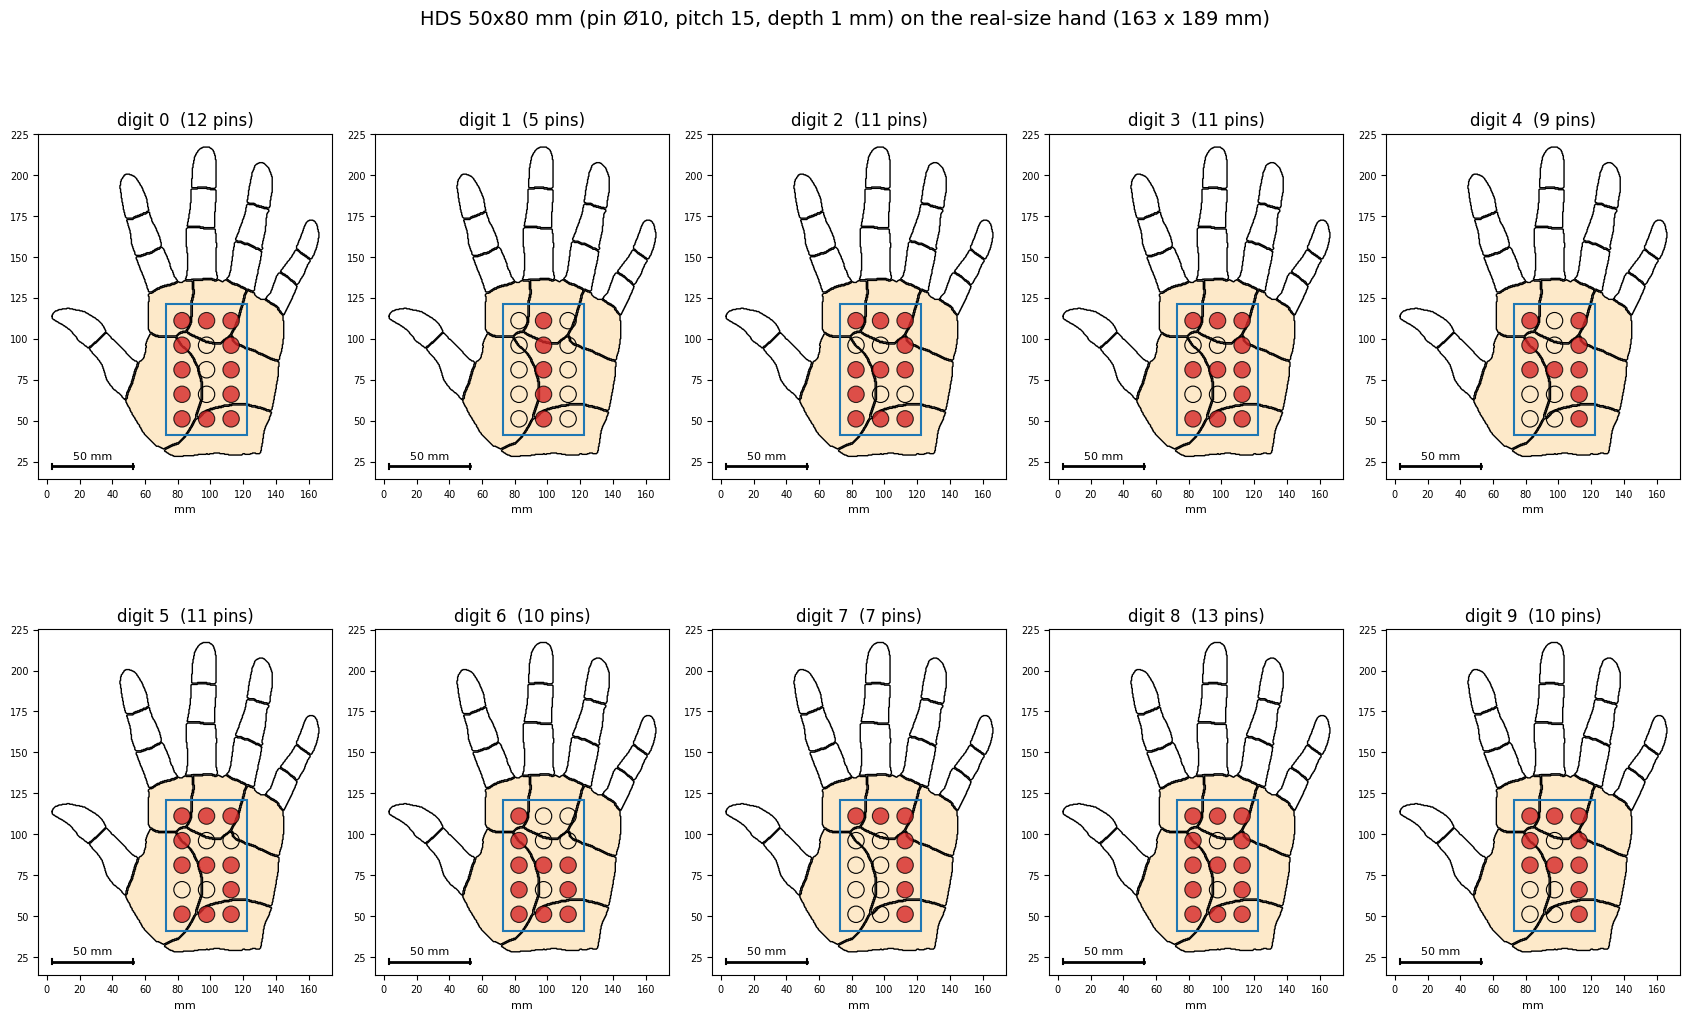

PDF 10 trang, mỗi trang 183 x 209 mm. In ở 100% (Actual size), kiểm tra thanh 50 mm bằng thước.


'\ntry:\n    from google.colab import files; files.download("out/digits_actual_size.pdf")\nexcept Exception: pass\n'

In [8]:
dims = hand_dimensions_mm(ts)
print(f"Bàn tay (đã scale về kích thước thật): rộng {dims['hand_width_mm']:.0f} mm x dài {dims['hand_length_mm']:.0f} mm, ngón giữa ~{dims['middle_finger_mm']:.0f} mm")
os.makedirs("out", exist_ok=True)
fig = plot_all_digits(ts, CENTER, highlight=tsa.PALM_REGIONS, savepath="out/digits_on_hand.png"); plt.show()
PAGE_W, PAGE_H = export_actual_size_pdf(ts, CENTER, "out/digits_actual_size.pdf", highlight=tsa.PALM_REGIONS)
print(f"PDF 10 trang, mỗi trang {PAGE_W:.0f} x {PAGE_H:.0f} mm. In ở 100% (Actual size), kiểm tra thanh 50 mm bằng thước.")
"""
try:
    from google.colab import files; files.download("out/digits_actual_size.pdf")
except Exception: pass
"""

## 7. Visualization response của TouchSim

In [9]:
def plot_response(resp, pop, tensor=None, center_px=None, duration=None, title=""):
    duration = spec.duration_s if duration is None else duration
    cls = np.array(pop.affclass); spikes = list(resp.spikes)
    counts = np.array([len(s) for s in spikes]); locs_px = hs.hand2pixel(pop.location)
    names = [c for c in ["SA1", "RA", "PC"] if c in set(cls)]
    colors = {"SA1": "tab:blue", "RA": "tab:green", "PC": "tab:orange"}
    fig = plt.figure(figsize=(15, 9)); gs = fig.add_gridspec(2, 3)
    ax = fig.add_subplot(gs[0, :2]); y = 0; ticks = []          # (a) raster theo loại afferent
    for nme in names:
        idx = np.where(cls == nme)[0]
        for i in idx:
            if len(spikes[i]): ax.plot(spikes[i], np.full(len(spikes[i]), y), "|", color=colors[nme], ms=3)
            y += 1
        ticks.append((y - len(idx)/2, nme)); ax.axhline(y, color="gray", lw=.5)
    ax.set_yticks([t[0] for t in ticks]); ax.set_yticklabels([t[1] for t in ticks])
    for t in np.arange(1, spec.rows) * spec.row_duration_s: ax.axvline(t, color="k", ls=":", lw=.6)
    ax.set_xlabel("time (s)"); ax.set_title("Spike raster theo loại afferent " + title)
    ax = fig.add_subplot(gs[0, 2])                              # (b) spike count theo loại
    ax.boxplot([counts[cls == n] for n in names], showmeans=True)
    ax.set_xticks(range(1, len(names)+1)); ax.set_xticklabels(names); ax.set_ylabel("spikes / afferent"); ax.set_title("Spike count theo loại")
    ax = fig.add_subplot(gs[1, 0]); bins = np.arange(0, duration + 1e-9, 0.05)   # (c) firing rate quần thể
    for nme in names:
        allsp = np.concatenate([spikes[i] for i in np.where(cls == nme)[0]] + [np.array([])])
        h, _ = np.histogram(allsp, bins); nn = max((cls == nme).sum(), 1)
        ax.plot(bins[:-1] + np.diff(bins)/2, h / nn / np.diff(bins), color=colors[nme], label=nme)
    for t in np.arange(1, spec.rows) * spec.row_duration_s: ax.axvline(t, color="k", ls=":", lw=.6)
    ax.set_xlabel("time (s)"); ax.set_ylabel("Hz / afferent"); ax.legend(); ax.set_title("Population firing rate")
    ax = fig.add_subplot(gs[1, 1:])                             # (d) bản đồ không gian trên bàn tay
    plot_hand(ax, highlight=[], labels=False)
    sc = ax.scatter(locs_px[:, 0], locs_px[:, 1], c=counts, s=12, cmap="inferno", zorder=3); plt.colorbar(sc, ax=ax, label="spikes")
    if tensor is not None: draw_pins(ax, tensor, center_px, PPM, ec="cyan", zorder=5, alpha=.3)
    ax.set_xlim(center_px[0]-110, center_px[0]+110) if center_px else None
    ax.set_ylim(center_px[1]-150, center_px[1]+150) if center_px else None
    ax.set_title("Spike count theo vị trí afferent (viền cyan = pin)")
    plt.tight_layout(); plt.show()
    return counts, cls

AfferentPopulation with 4123 afferent(s): 1178 SA1, 2356 RA, 589 PC.
Timing per row: ramp 0.2s + hold 0.6s + ramp 0.2s = 1.0s; 5 rows = 5.0s
digit 0: 12 pin, 5867 spikes, per row [1506, 955, 984, 968, 1453]


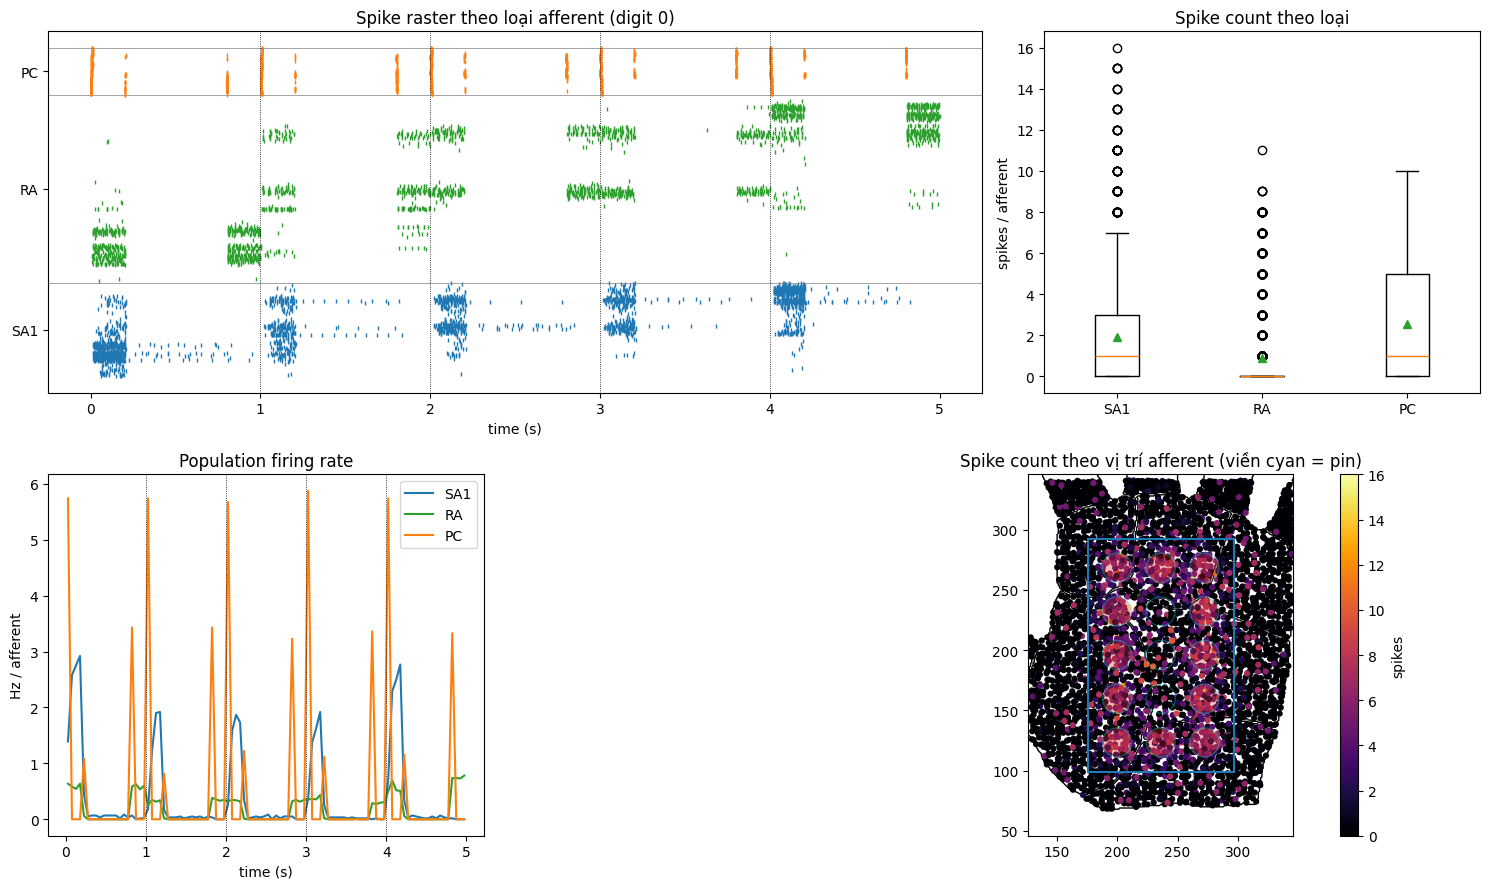

digit 1: 5 pin, 2523 spikes, per row [595, 469, 492, 488, 479]


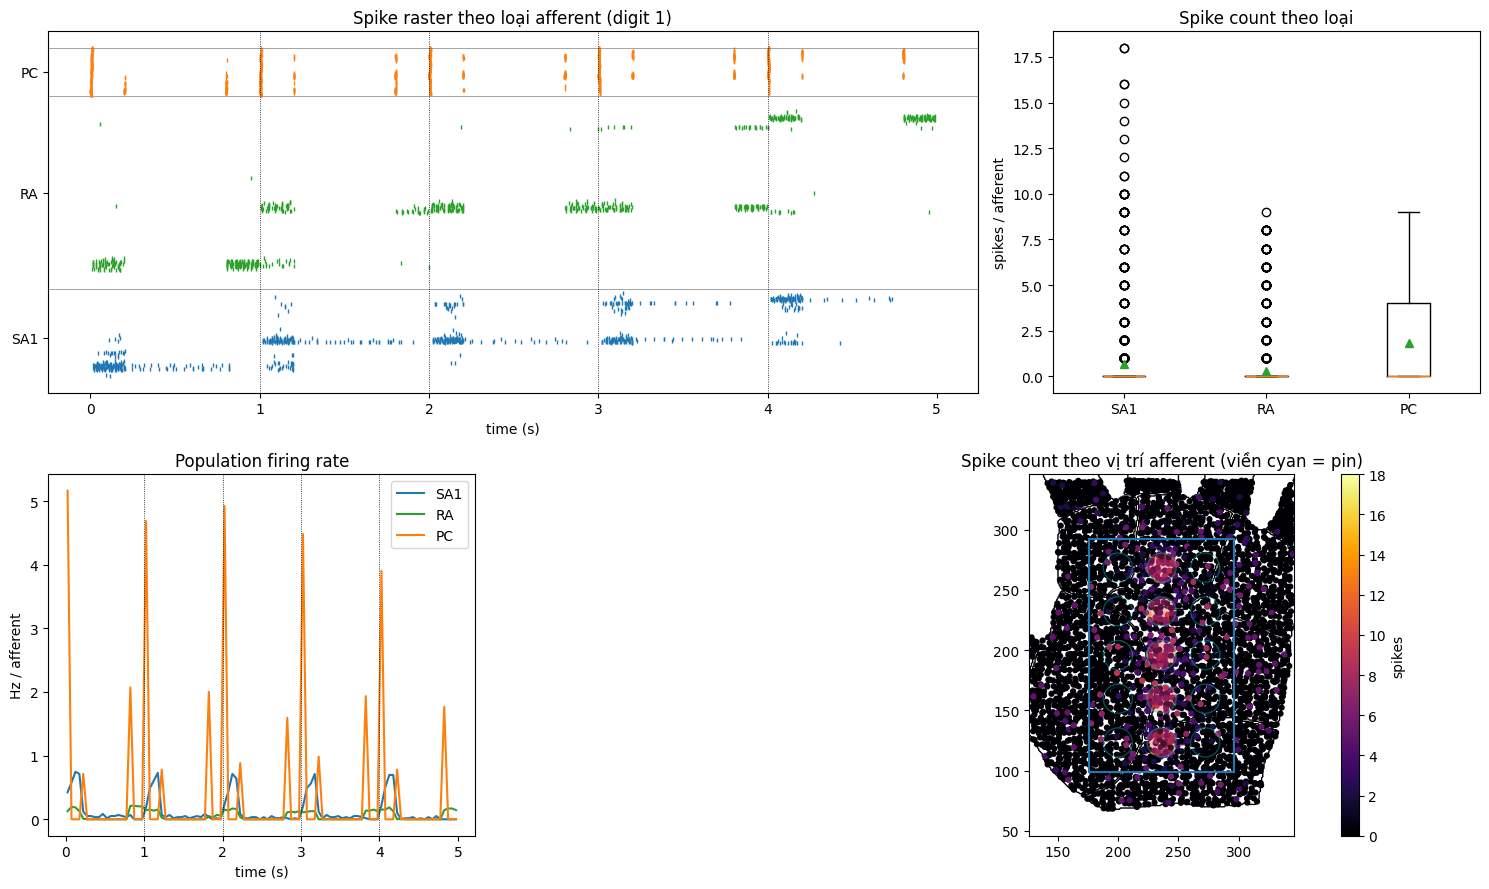

digit 2: 11 pin, 5431 spikes, per row [1536, 484, 1481, 486, 1444]


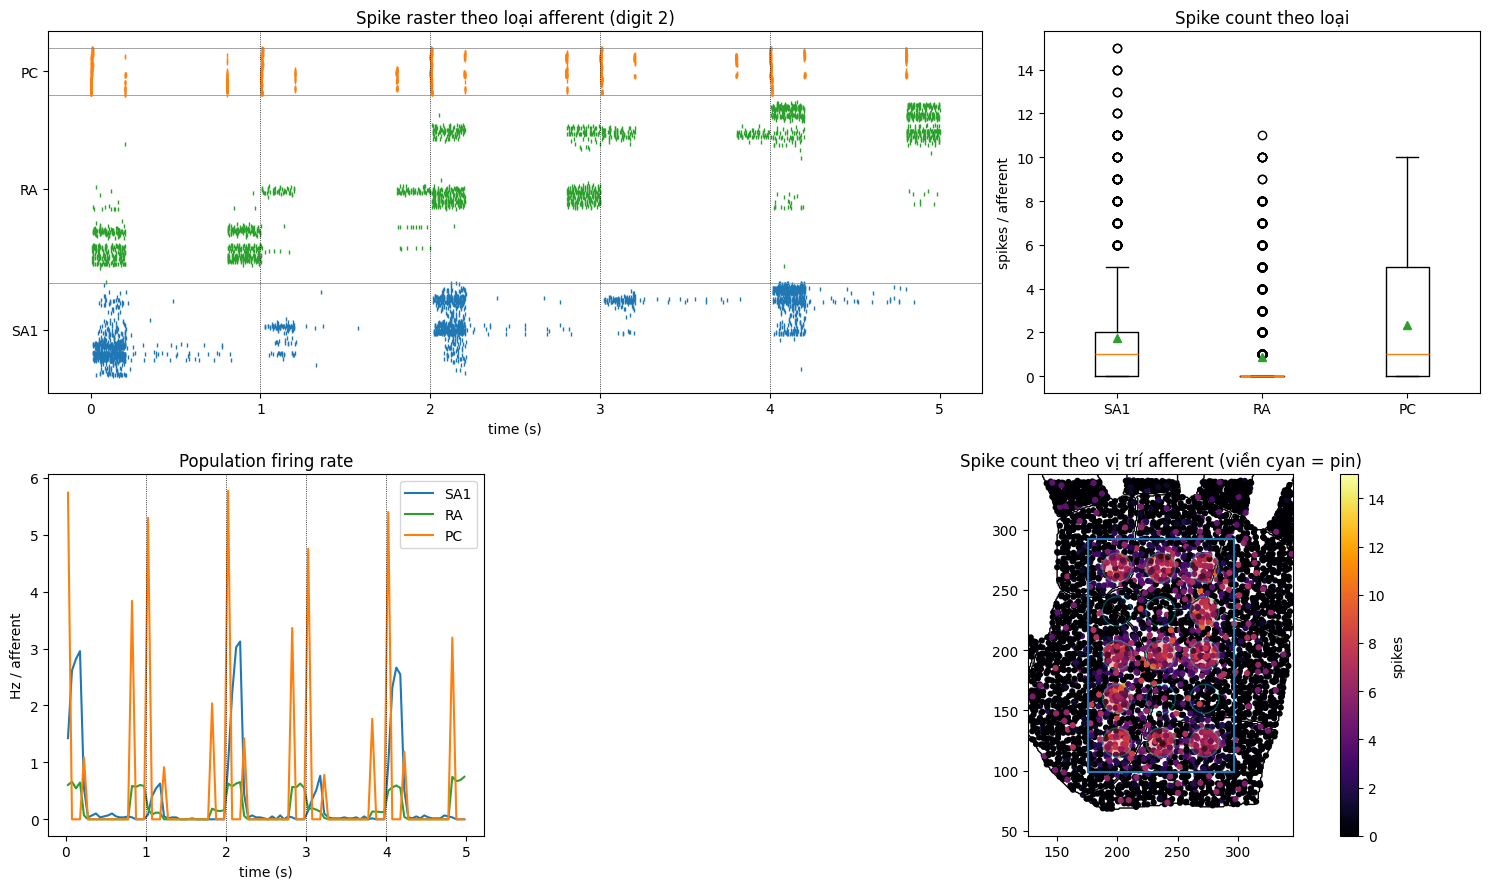

digit 3: 11 pin, 5375 spikes, per row [1502, 479, 1449, 483, 1462]


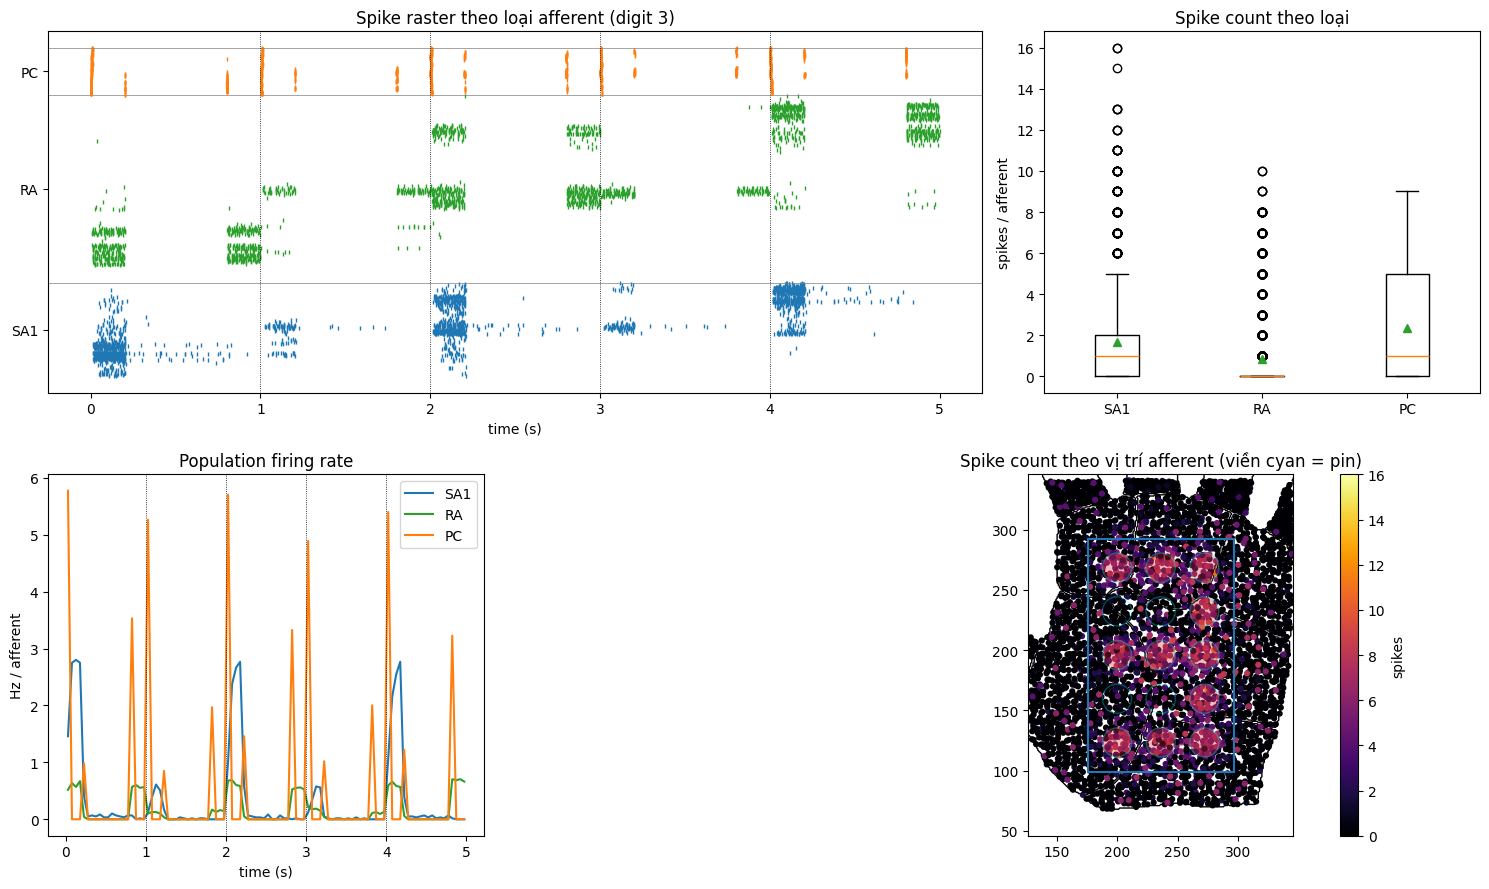

digit 4: 9 pin, 4443 spikes, per row [1043, 956, 1434, 502, 508]


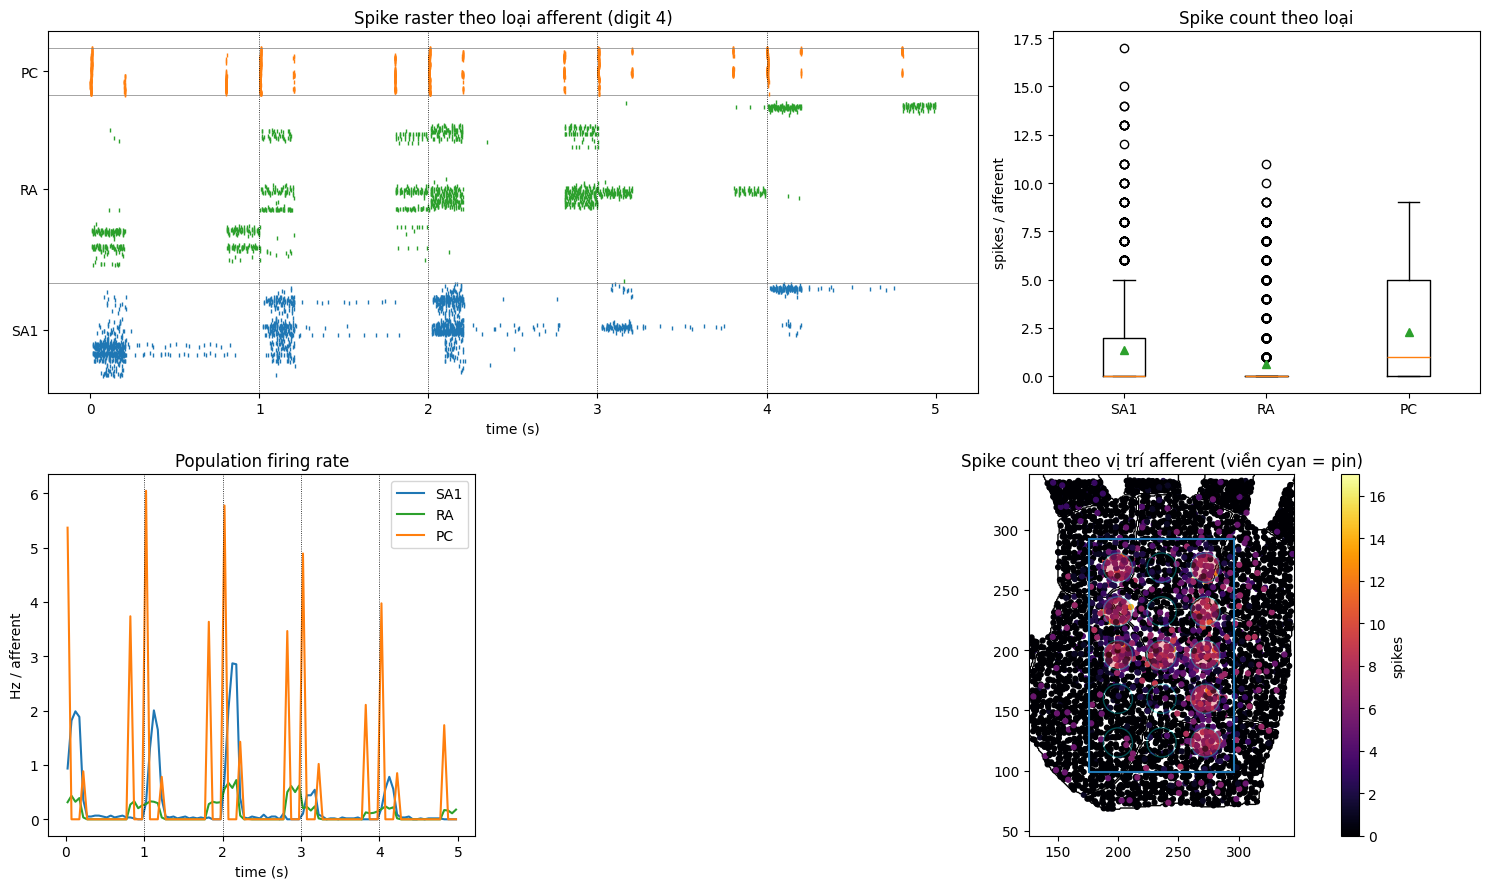

digit 5: 11 pin, 5451 spikes, per row [1502, 504, 1470, 498, 1477]


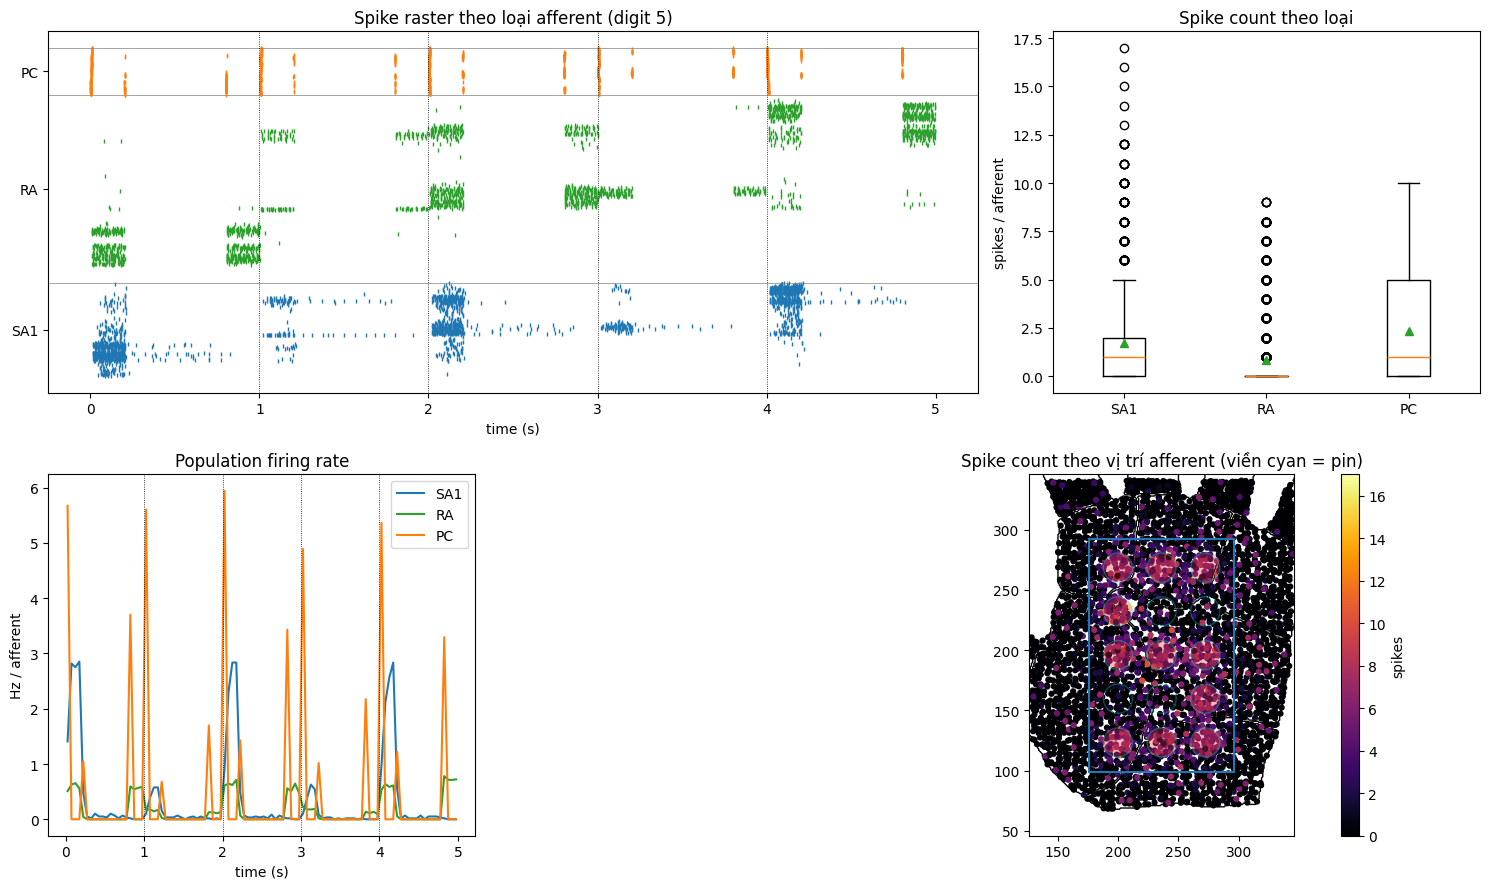

digit 6: 10 pin, 4863 spikes, per row [521, 470, 1461, 977, 1434]


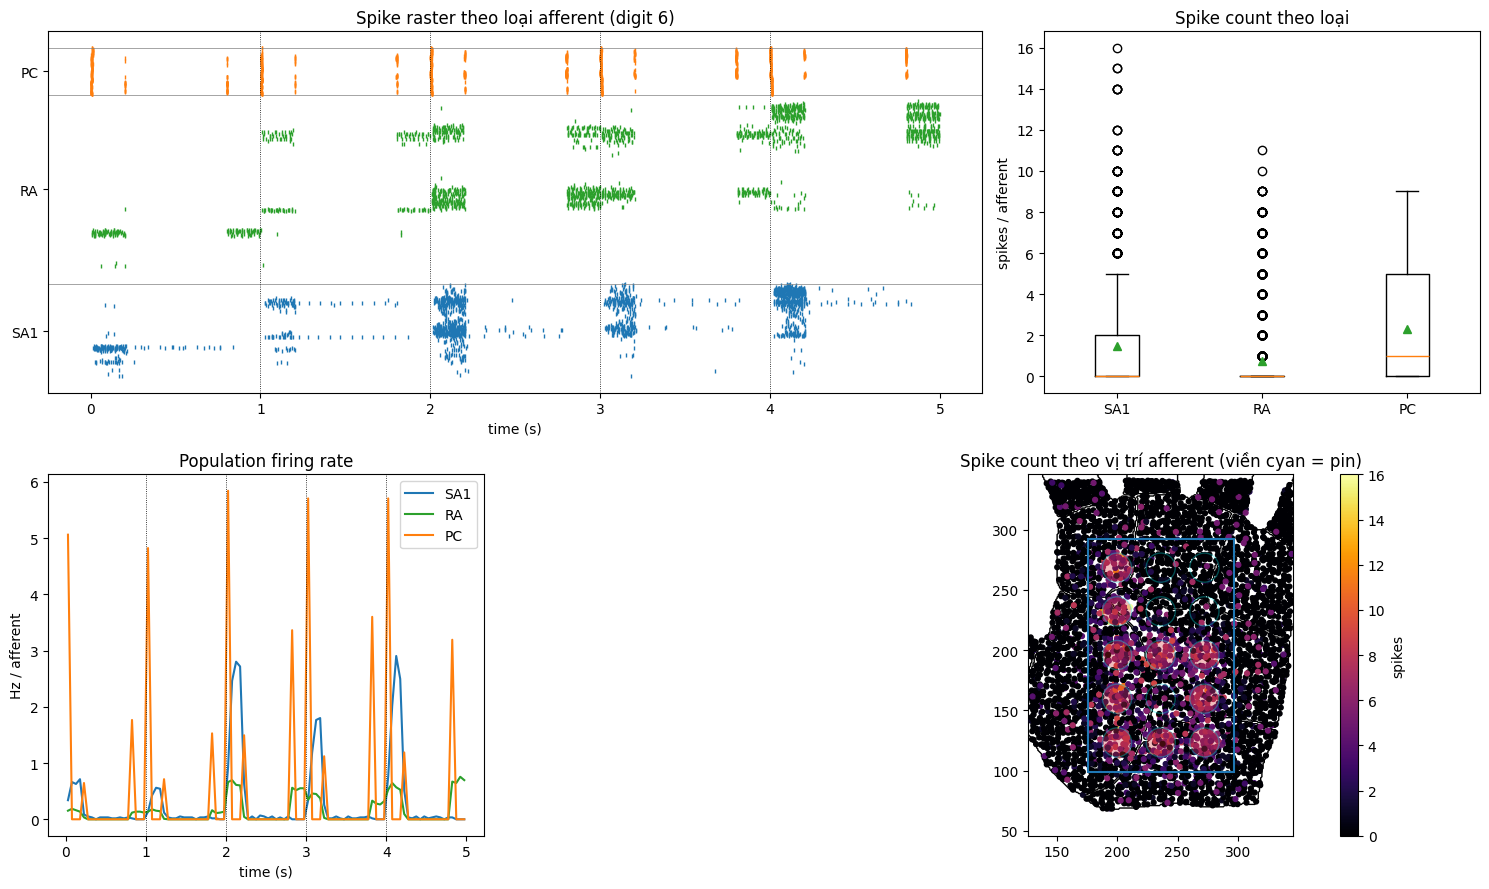

digit 7: 7 pin, 3546 spikes, per row [1516, 489, 538, 499, 504]


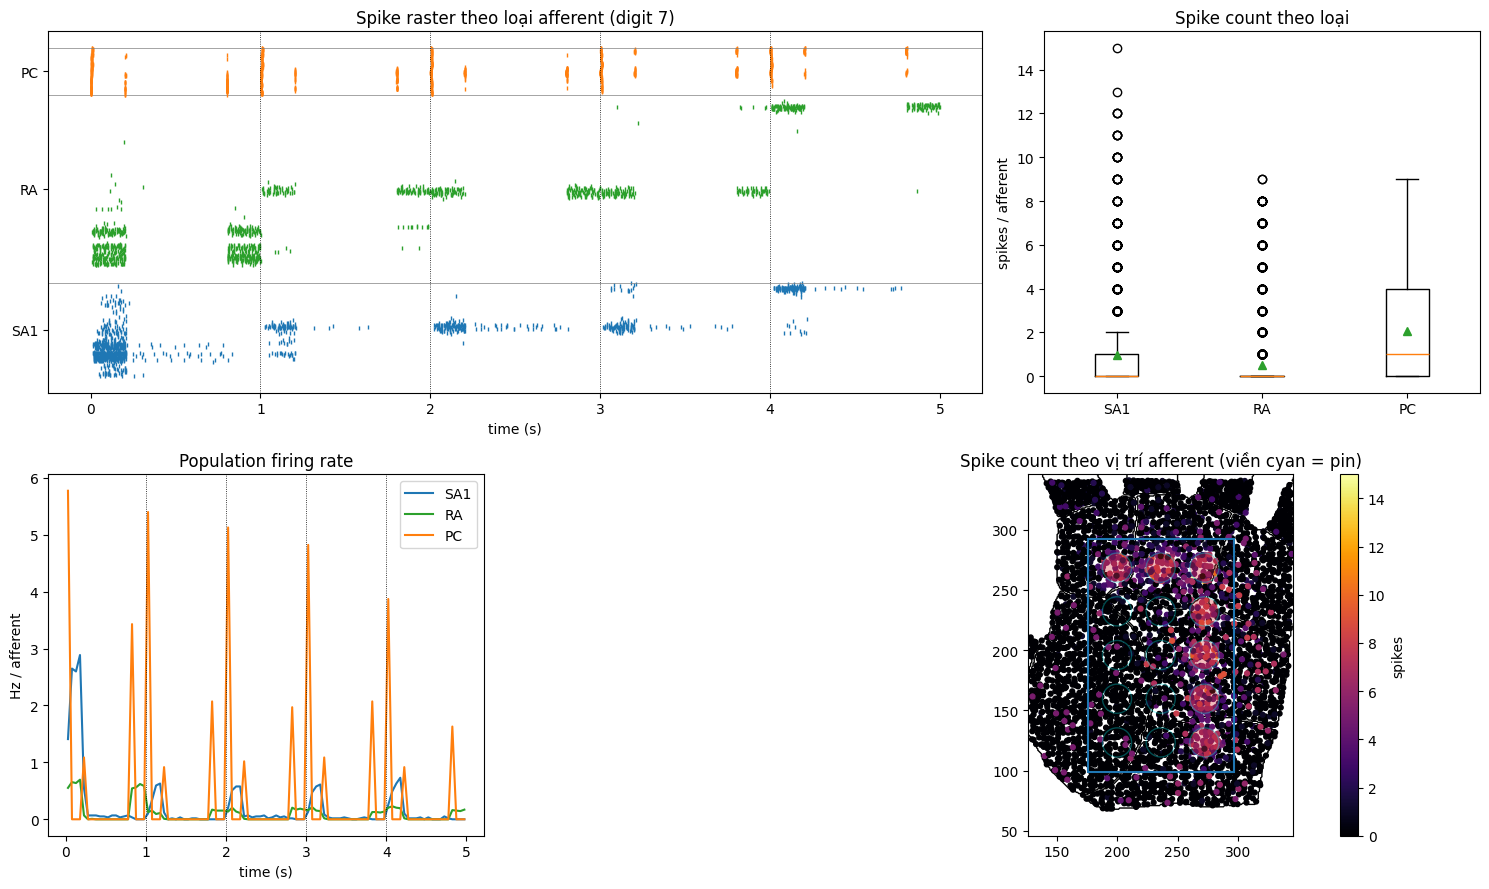

digit 8: 13 pin, 6351 spikes, per row [1525, 934, 1440, 976, 1476]


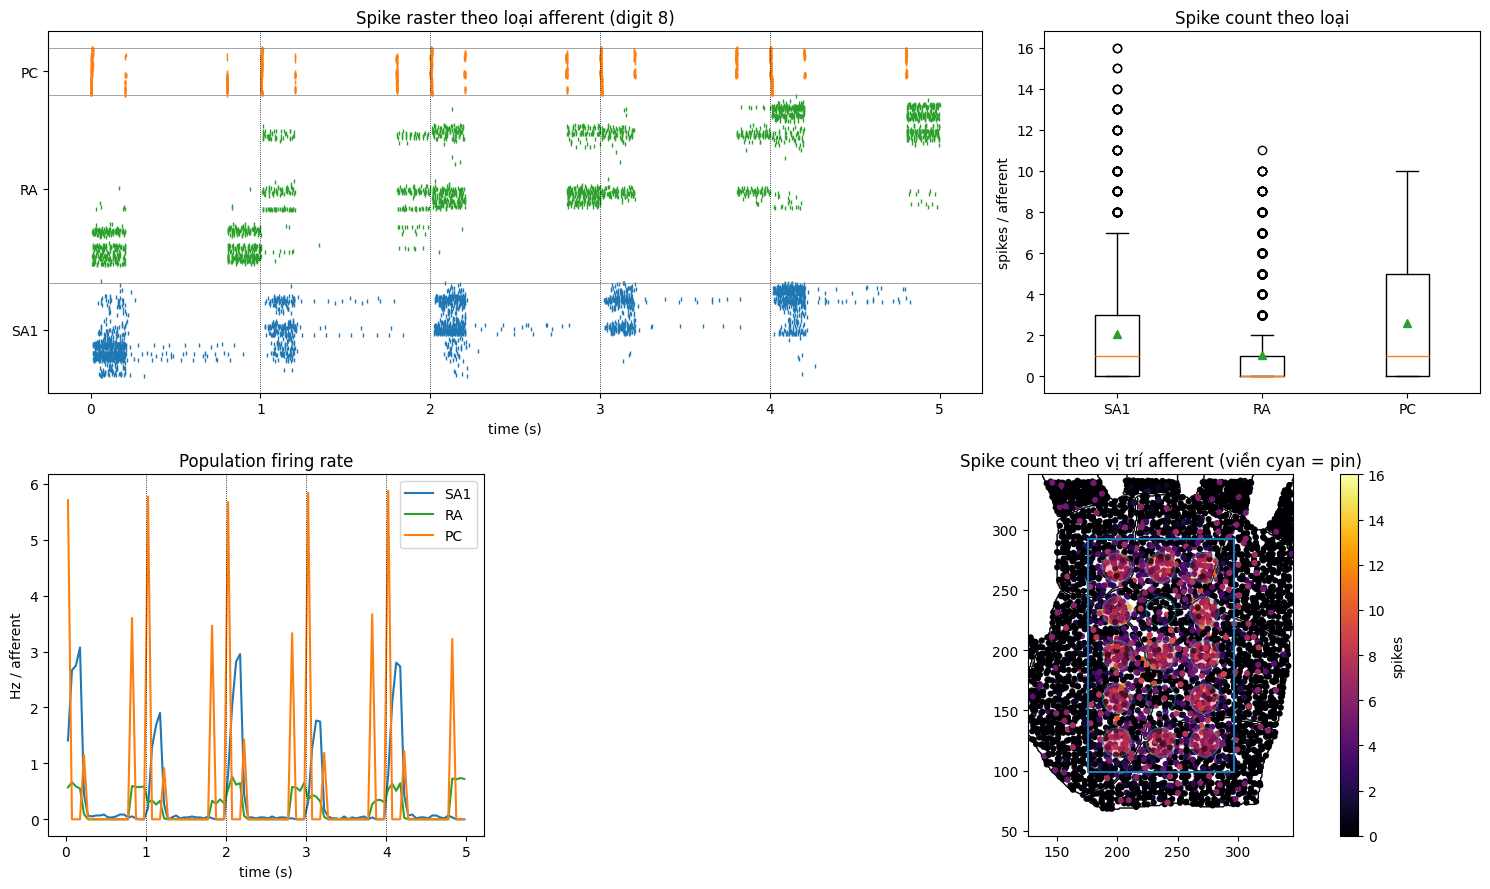

digit 9: 10 pin, 4898 spikes, per row [1507, 932, 1432, 514, 513]


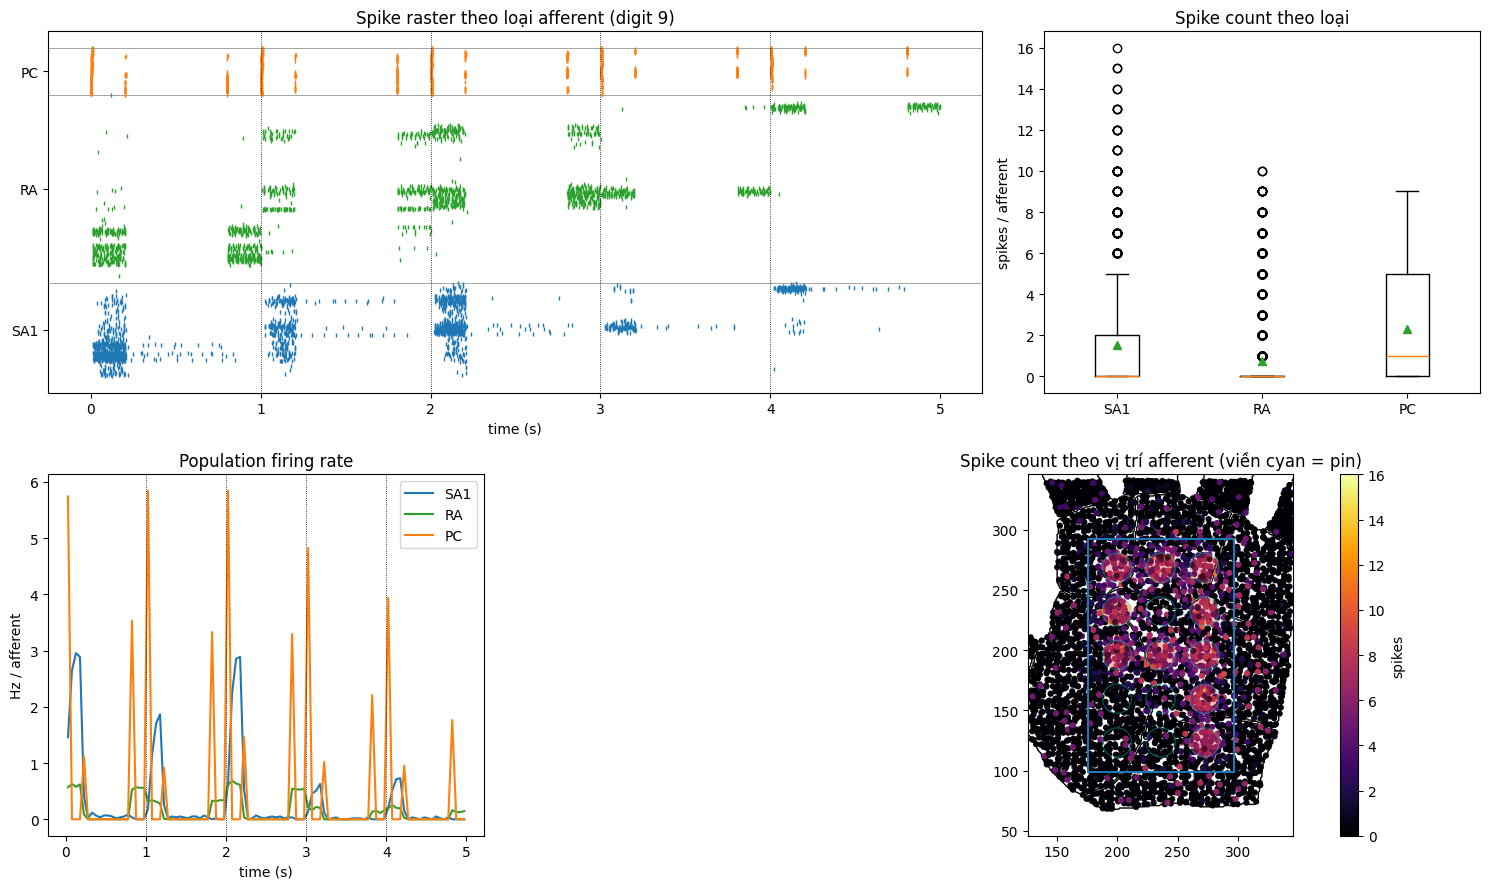

In [10]:
def spike_counts(resp):
    """Return Numpy array include the amount of spike counts in each afferent."""
    return np.array([len(s) for s in resp.spikes])

def spike_counts_by_row(resp, n_rows, row_duration_s):
    """(n_rows, N) spikes of every afferent inside the time window of each HDS row."""
    edges = np.arange(n_rows + 1) * row_duration_s
    return np.array([[np.count_nonzero((s >= edges[r]) & (s < edges[r + 1])) for s in resp.spikes]
                     for r in range(n_rows)])

def evaluate(counts_a, counts_b):
    """Tính độ tương quan Pearson r giữa 2 phản hồi phản ánh mức độ tương đồng."""
    if np.std(counts_a) == 0 or np.std(counts_b) == 0:
        return 0.0
    return float(np.corrcoef(counts_a, counts_b)[0, 1])

# 7.1 Response của cả 10 chữ số (quần thể = afferent dưới HDS + lề 20 mm; density_multiplier<1 nếu muốn nhanh hơn)
# Mỗi hàng: xuống 0.2 s -> giữ 0.6 s -> lên 0.2 s, rồi sang hàng kế (spec.ramp_s / spec.hold_s)
pop = tsa.make_population(ts, spec, CENTER, density_multiplier=1.0)
print(pop)
print(f"Timing per row: ramp {spec.ramp_s}s + hold {spec.hold_s}s + ramp {spec.ramp_s}s = {spec.row_duration_s}s; {spec.rows} rows = {spec.duration_s}s")
all_counts, all_resp = {}, {}
for d in range(10):
    tensor = digit_tensor(d)
    stim = tsa.build_stimulus(ts, tensor, spec, CENTER)
    resp = tsa.respond(ts, stim, pop)
    all_resp[d] = resp
    all_counts[d] = spike_counts(resp)
    by_row = spike_counts_by_row(resp, spec.rows, spec.row_duration_s).sum(axis=1)
    print(f"digit {d}: {int(tensor.sum())} pin, {all_counts[d].sum()} spikes, per row {by_row.tolist()}")
    plot_response(resp, pop, tensor, CENTER, title=f"(digit {d})")

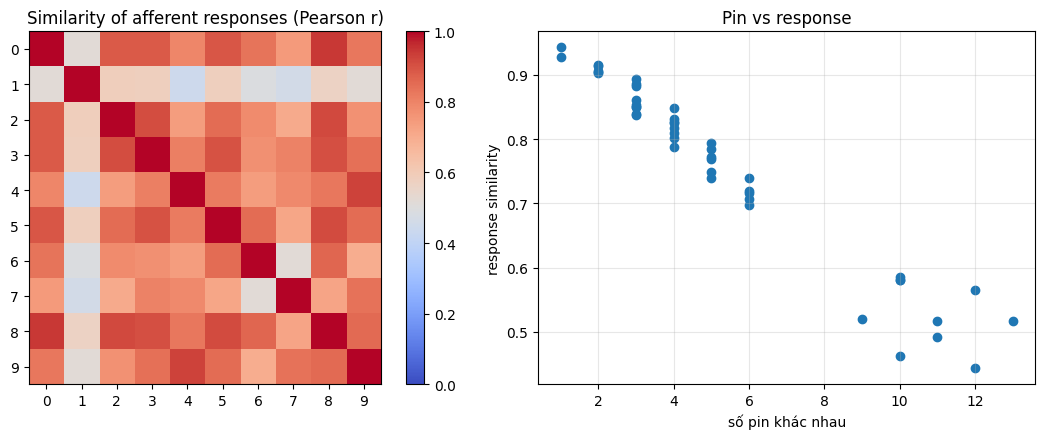

In [11]:
# 7.2 Ma trận giống nhau của response giữa 10 chữ số (dùng để đánh giá decoder) và so với khoảng cách pin
# dùng lại all_counts / all_resp đã tính ở 7.1
S = np.array([[evaluate(all_counts[a], all_counts[b]) for b in range(10)] for a in range(10)])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im = axes[0].imshow(S, vmin=min(np.nanmin(S), 0), vmax=1, cmap="coolwarm"); plt.colorbar(im, ax=axes[0])
axes[0].set_xticks(range(10)); axes[0].set_yticks(range(10)); axes[0].set_title("Similarity of afferent responses (Pearson r)")
iu = np.triu_indices(10, 1); axes[1].scatter(H[iu], S[iu])
axes[1].set_xlabel("số pin khác nhau"); axes[1].set_ylabel("response similarity"); axes[1].set_title("Pin vs response"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### 7.3 Spike map của cả 10 chữ số (hàng HDS, SA1, RA, PC), kiểu hình trong paper

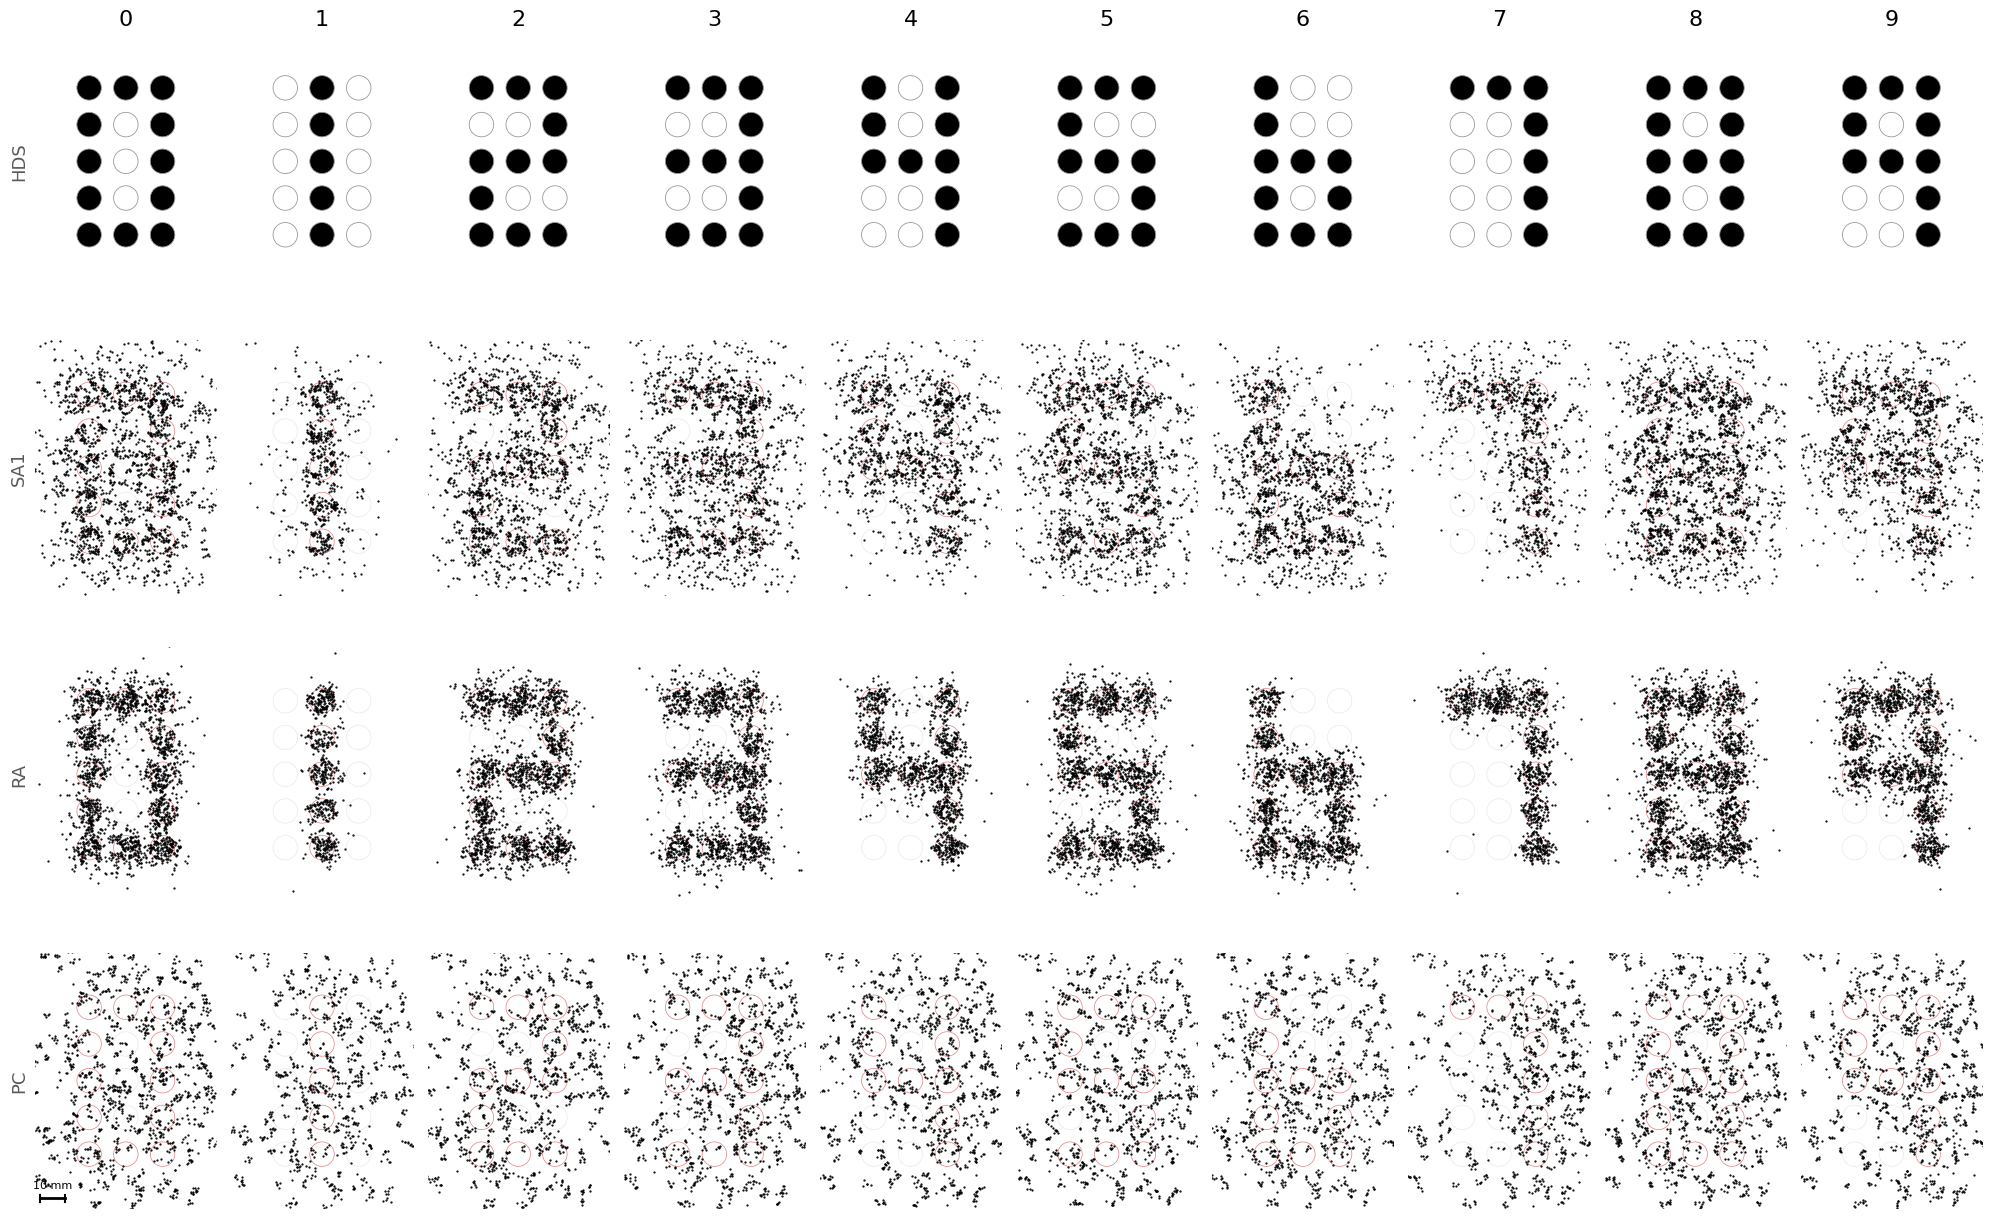

'\ntry:\n    from google.colab import files; files.download("out/spike_maps_all_digits.png")\nexcept Exception: pass\n'

In [12]:
fig = plot_spike_maps(ts, pop, all_resp, CENTER, savepath="out/spike_maps_all_digits.png"); plt.show()
"""
try:
    from google.colab import files; files.download("out/spike_maps_all_digits.png")
except Exception: pass
"""